# k-NN V2

For this experiment, I wanted to see how changing k affects the accuracy. I tested k=1, 3, 5, 10 and 20 on both datasets, using the same training and validation samples as before.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys

import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data_loader import load_task, split_train_val
from src.models.knn import KNNClassifier

k_values = [1, 3, 5, 10, 20]


I started by testing the different k values on the image dataset.

In [2]:
X, y, image_X_test, image_test_ids = load_task("image")
X_train, X_val, y_train, y_val = split_train_val(
    X, y, val_fraction=0.2, seed=42
)
image_X_train = X_train[:1000]
image_y_train = y_train[:1000]
X_val_v2 = X_val[:200]
y_val_v2 = y_val[:200]

result_dir = project_root / "results" / "image"
v1_summary = pd.read_csv(result_dir / "knn_v1_summary.csv")
v1_validation = pd.read_csv(result_dir / "knn_v1_validation.csv")
assert v1_validation["validation_index"].tolist() == list(range(len(y_val_v2)))
assert v1_validation["actual_label"].tolist() == y_val_v2.tolist()

image_rows = []
image_predictions = {}
image_best_accuracy = -1
print("Image: 1000 training samples, 200 validation samples")
for k in k_values:
    clf = KNNClassifier(k=k)
    clf.fit(image_X_train, image_y_train)
    start = perf_counter()
    y_pred = clf.predict(X_val_v2)
    prediction_time = perf_counter() - start
    accuracy = sum(p == t for p, t in zip(y_pred, y_val_v2)) / len(y_val_v2)
    image_predictions[k] = y_pred

    image_rows.append({
        "dataset": "image",
        "version": "V2",
        "k": k,
        "distance_metric": "euclidean",
        "voting_method": "majority",
        "normalized": False,
        "training_samples": len(image_X_train),
        "validation_samples": len(X_val_v2),
        "validation_accuracy": accuracy,
        "prediction_time_seconds": prediction_time,
    })
    print(f"k={k:2d}  accuracy={accuracy:.2%}  prediction time={prediction_time:.6f} s")

    # k values are ascending, so an accuracy tie keeps the smaller k.
    if accuracy > image_best_accuracy:
        image_best_k = k
        image_best_accuracy = accuracy
        best_predictions = y_pred
    if k == 3:
        assert accuracy == v1_summary.loc[0, "validation_accuracy"]
        assert y_pred == v1_validation["predicted_label"].tolist()

image_summary = pd.DataFrame(image_rows)
image_summary.to_csv(result_dir / "knn_v2_summary.csv", index=False)
pd.DataFrame({
    "validation_index": range(len(y_val_v2)),
    "actual_label": y_val_v2,
    "predicted_label": best_predictions,
}).to_csv(result_dir / "knn_v2_validation.csv", index=False)
print(f"Best k: {image_best_k}, validation accuracy: {image_best_accuracy:.2%}")


Image: 1000 training samples, 200 validation samples
k= 1  accuracy=21.50%  prediction time=1.767608 s
k= 3  accuracy=21.00%  prediction time=3.671023 s
k= 5  accuracy=20.00%  prediction time=2.897174 s
k=10  accuracy=16.50%  prediction time=3.016762 s
k=20  accuracy=14.50%  prediction time=2.184655 s
Best k: 1, validation accuracy: 21.50%


Then I did the same thing for the sentiment dataset.

In [3]:
X, y, sentiment_X_test, sentiment_test_ids = load_task("sentiment")
X_train, X_val, y_train, y_val = split_train_val(
    X, y, val_fraction=0.2, seed=42
)
sentiment_X_train = X_train[:1000]
sentiment_y_train = y_train[:1000]
X_val_v2 = X_val[:200]
y_val_v2 = y_val[:200]

result_dir = project_root / "results" / "sentiment"
v1_summary = pd.read_csv(result_dir / "knn_v1_summary.csv")
v1_validation = pd.read_csv(result_dir / "knn_v1_validation.csv")
assert v1_validation["validation_index"].tolist() == list(range(len(y_val_v2)))
assert v1_validation["actual_label"].tolist() == y_val_v2.tolist()

sentiment_rows = []
sentiment_predictions = {}
sentiment_best_accuracy = -1
print("Sentiment: 1000 training samples, 200 validation samples")
for k in k_values:
    clf = KNNClassifier(k=k)
    clf.fit(sentiment_X_train, sentiment_y_train)
    start = perf_counter()
    y_pred = clf.predict(X_val_v2)
    prediction_time = perf_counter() - start
    accuracy = sum(p == t for p, t in zip(y_pred, y_val_v2)) / len(y_val_v2)
    sentiment_predictions[k] = y_pred

    sentiment_rows.append({
        "dataset": "sentiment",
        "version": "V2",
        "k": k,
        "distance_metric": "euclidean",
        "voting_method": "majority",
        "normalized": False,
        "training_samples": len(sentiment_X_train),
        "validation_samples": len(X_val_v2),
        "validation_accuracy": accuracy,
        "prediction_time_seconds": prediction_time,
    })
    print(f"k={k:2d}  accuracy={accuracy:.2%}  prediction time={prediction_time:.6f} s")

    # k values are ascending, so an accuracy tie keeps the smaller k.
    if accuracy > sentiment_best_accuracy:
        sentiment_best_k = k
        sentiment_best_accuracy = accuracy
        best_predictions = y_pred
    if k == 3:
        assert accuracy == v1_summary.loc[0, "validation_accuracy"]
        assert y_pred == v1_validation["predicted_label"].tolist()

sentiment_summary = pd.DataFrame(sentiment_rows)
sentiment_summary.to_csv(result_dir / "knn_v2_summary.csv", index=False)
pd.DataFrame({
    "validation_index": range(len(y_val_v2)),
    "actual_label": y_val_v2,
    "predicted_label": best_predictions,
}).to_csv(result_dir / "knn_v2_validation.csv", index=False)
print(f"Best k: {sentiment_best_k}, validation accuracy: {sentiment_best_accuracy:.2%}")


Sentiment: 1000 training samples, 200 validation samples
k= 1  accuracy=49.00%  prediction time=2.435719 s
k= 3  accuracy=57.50%  prediction time=1.842381 s
k= 5  accuracy=53.00%  prediction time=1.849037 s
k=10  accuracy=52.50%  prediction time=2.002372 s
k=20  accuracy=56.00%  prediction time=1.731739 s
Best k: 3, validation accuracy: 57.50%


I plotted the accuracies to compare how the results change with k.

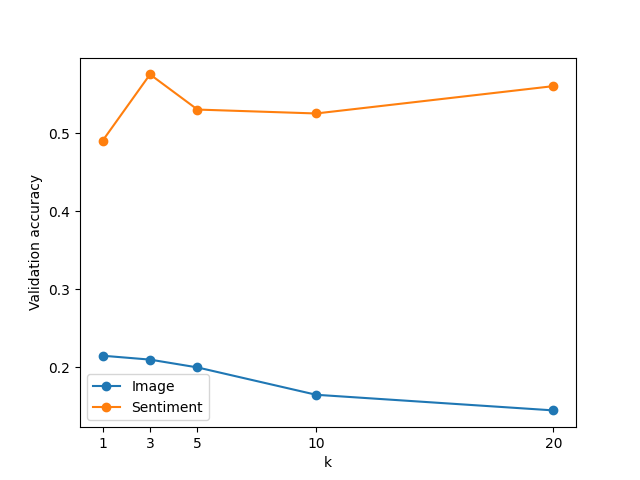

In [4]:
knn_result_dir = project_root / "results" / "knn"
knn_result_dir.mkdir(parents=True, exist_ok=True)

plt.figure()
plt.plot(k_values, image_summary["validation_accuracy"], marker="o", label="Image")
plt.plot(k_values, sentiment_summary["validation_accuracy"], marker="o", label="Sentiment")
plt.xlabel("k")
plt.ylabel("Validation accuracy")
plt.xticks(k_values)
plt.legend()
plt.savefig(knn_result_dir / "knn_v2_accuracy.png")
plt.show()


Finally, I compared the best results for both datasets.

In [5]:
print(f"Image:     k={image_best_k}, accuracy={image_best_accuracy:.2%}")
print(f"Sentiment: k={sentiment_best_k}, accuracy={sentiment_best_accuracy:.2%}")


Image:     k=1, accuracy=21.50%
Sentiment: k=3, accuracy=57.50%


I used the best k for each dataset to predict the test labels, keeping the same 1000 training samples.

In [6]:
image_clf = KNNClassifier(k=image_best_k)
image_clf.fit(image_X_train, image_y_train)
start = perf_counter()
image_test_predictions = image_clf.predict(image_X_test)
print(f"Image: predicted {len(image_test_predictions)} test labels in {perf_counter() - start:.2f} s")

sentiment_clf = KNNClassifier(k=sentiment_best_k)
sentiment_clf.fit(sentiment_X_train, sentiment_y_train)
start = perf_counter()
sentiment_test_predictions = sentiment_clf.predict(sentiment_X_test)
print(f"Sentiment: predicted {len(sentiment_test_predictions)} test labels in {perf_counter() - start:.2f} s")


Image: predicted 5000 test labels in 41.97 s
Sentiment: predicted 5000 test labels in 69.46 s


I matched the predictions to the sample submission order and checked the IDs and labels before saving.

In [7]:
image_predictions = pd.DataFrame({"id": image_test_ids, "label": image_test_predictions})
sentiment_predictions = pd.DataFrame({"id": sentiment_test_ids, "label": sentiment_test_predictions})
assert len(image_predictions) == 5000 and len(sentiment_predictions) == 5000
assert image_predictions["label"].between(0, 49).all()
assert sentiment_predictions["label"].between(0, 2).all()

predictions = pd.concat([image_predictions, sentiment_predictions], ignore_index=True)
sample_submission = pd.read_csv(project_root / "data" / "raw" / "sample_submission.csv")
assert len(predictions) == 10000 and len(sample_submission) == 10000
assert predictions["id"].is_unique and sample_submission["id"].is_unique
assert set(predictions["id"]) == set(sample_submission["id"])

# A left merge keeps the sample submission's ID order.
submission = sample_submission[["id"]].merge(predictions, on="id", how="left", sort=False)
assert submission.columns.tolist() == ["id", "label"]
assert submission["id"].tolist() == sample_submission["id"].tolist()
assert not submission.isna().any().any()
assert pd.api.types.is_integer_dtype(submission["label"])

submission_dir = project_root / "submission" / "knn"
submission_dir.mkdir(parents=True, exist_ok=True)
submission_path = submission_dir / "submission_v2_knn.csv"
submission.to_csv(submission_path, index=False)
saved_submission = pd.read_csv(submission_path)
assert pd.api.types.is_integer_dtype(saved_submission["label"])
pd.testing.assert_frame_equal(saved_submission, submission, check_dtype=False)
print("Saved and checked 10000 predictions in", submission_path)


Saved and checked 10000 predictions in C:\Users\user\OneDrive\Documentos\Fall2026\COMP472\team_project\COMP472\submission\knn\submission_v2_knn.csv


I recorded the validation results and left the Kaggle scores empty because I have not uploaded the submission.

In [8]:
image_v1 = pd.read_csv(project_root / "results" / "image" / "knn_v1_summary.csv")
sentiment_v1 = pd.read_csv(project_root / "results" / "sentiment" / "knn_v1_summary.csv")
tracker_rows = [
    {
        "version": "V1",
        "image_validation_accuracy": image_v1.loc[0, "validation_accuracy"],
        "sentiment_validation_accuracy": sentiment_v1.loc[0, "validation_accuracy"],
        "kaggle_public_score": "",
        "submitted_to_kaggle": False,
        "submission_filename": "",
        "notes": "k=3 and 1,000 training samples per dataset.",
    },
    {
        "version": "V2",
        "image_validation_accuracy": image_best_accuracy,
        "sentiment_validation_accuracy": sentiment_best_accuracy,
        "kaggle_public_score": "",
        "submitted_to_kaggle": False,
        "submission_filename": submission_path.name,
        "notes": f"Tested k=1, 3, 5, 10, 20; best image k={image_best_k}, sentiment k={sentiment_best_k}.",
    },
]
tracker_path = knn_result_dir / "kaggle_scores.csv"
if tracker_path.exists():
    tracker = pd.read_csv(tracker_path, keep_default_na=False)
    for row in tracker_rows:
        matching = tracker["version"] == row["version"]
        if matching.any():
            for column in ("image_validation_accuracy", "sentiment_validation_accuracy"):
                tracker.loc[matching, column] = row[column]
            for column in ("submission_filename", "notes"):
                empty = matching & (tracker[column] == "")
                tracker.loc[empty, column] = row[column]
        else:
            tracker = pd.concat([tracker, pd.DataFrame([row])], ignore_index=True)
else:
    tracker = pd.DataFrame(tracker_rows)
tracker.to_csv(tracker_path, index=False)
print(tracker.to_string(index=False))


version  image_validation_accuracy  sentiment_validation_accuracy kaggle_public_score  submitted_to_kaggle   submission_filename                                                    notes
     V1                      0.210                          0.575                                    False                                    k=3 and 1,000 training samples per dataset.
     V2                      0.215                          0.575                                    False submission_v2_knn.csv Tested k=1, 3, 5, 10, 20; best image k=1, sentiment k=3.
